# Active Parameter Fit on Simulated Sampler

In [1]:
%load_ext line_profiler

In [2]:
from functools import partial
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import norm

from prisma.apf.api import ActiveParameterFitEI
from prisma.physics_models.jax import beem_integral_f_vector_j
from prisma.physics_models.python import Ibeem_vector
from prisma.plot.plot_lib import plot_function_targets
from prisma.samplers.pseudorandom.noise import RandomNoiseSampler
from prisma.samplers.pseudorandom.function import \
    PrecomputedNoiseVectorizedJAXFunctionDomainSampler

In [3]:
np.random.seed(1)

import jax
jax.config.update('jax_enable_x64', True)

# Experimental Parameters

In [4]:
N = 100
x = np.linspace(0., 1.5, N) # (N x 1)
w = np.array([-.050, .87, -1e-5]) # (M x 1)
nonlin_f_w = partial(beem_integral_f_vector_j, w=w)
sigma_f = .001 # function standard deviation

# Precomputed Target Noise

In [5]:
t_noise_rv = norm(scale=sigma_f)
t_noise_sampler = RandomNoiseSampler(t_noise_rv)
t_noise_np = np.array(t_noise_sampler.sample(N))
t_sampler = PrecomputedNoiseVectorizedJAXFunctionDomainSampler(nonlin_f_w, t_noise_np)

In [6]:
y = np.array(nonlin_f_w(x))
t = np.array([t_sampler.sample(x_i) for x_i in x])

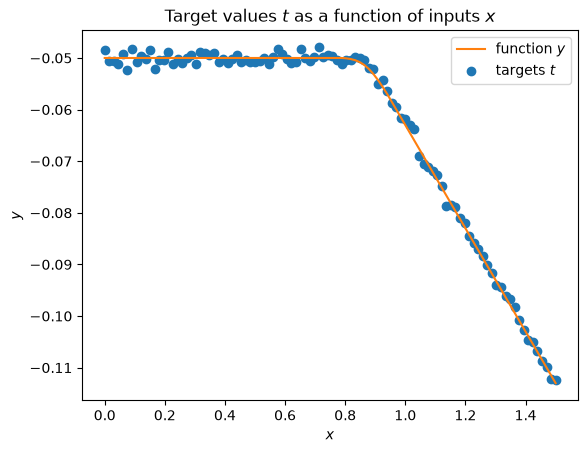

In [7]:
plot_function_targets(x, y, t, function_label="function $y$")

# NLR Parameter Estimation

In [8]:
p0_cf = np.array([-5e-2, .8, -1e-5])

In [9]:
cf_opt, cf_cov = curve_fit(Ibeem_vector, x, t, p0=p0_cf)

In [10]:
cf_opt

array([-5.00254821e-02,  8.74243008e-01, -1.00681396e-05])

In [11]:
y_cf = Ibeem_vector(x, *cf_opt)

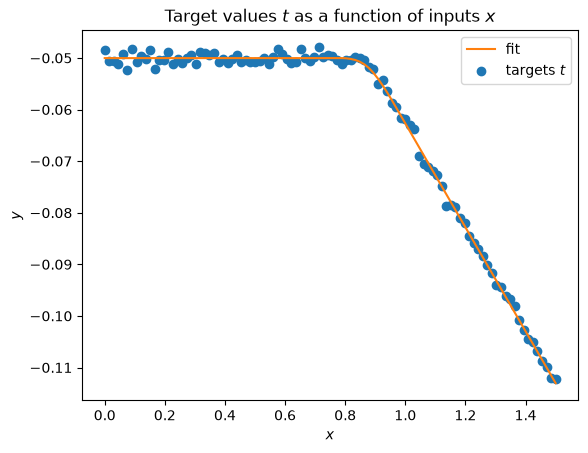

In [12]:
plot_function_targets(x, y_cf, t, function_label="fit")

# Rescale Data

In [13]:
scale_coef = -1.
in_min = 0.
in_max = .2
out_min = 0.
out_max = 100.

In [14]:
t_sampler.reset()
t_sampler.scale_coef = scale_coef
t_sampler.set_rescaling_bounds(in_min, in_max, out_min, out_max)
t_p = np.array([t_sampler.sample(x_i) for x_i in x])

In [15]:
cf_opt_p, cf_cov_p = curve_fit(Ibeem_vector, x, t_p)

In [16]:
cf_opt_p

array([2.50127409e+01, 8.74242993e-01, 5.03406967e-03])

In [17]:
y_cf_p = Ibeem_vector(x, *cf_opt_p)

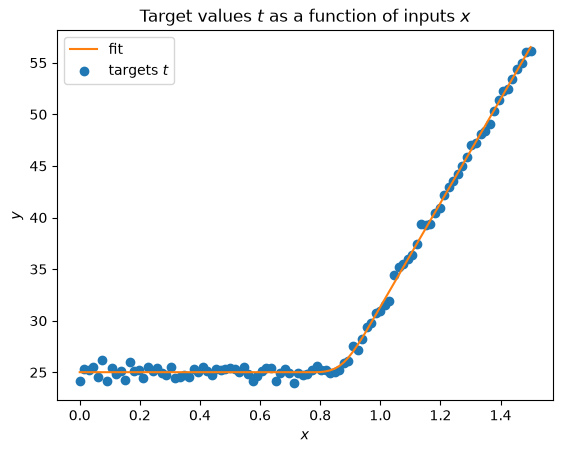

In [18]:
plot_function_targets(x, y_cf_p, t_p, function_label="fit")

# Active Parameter Fit Sampling

In [19]:
sample_ct = 10
m_0 = np.array([25., .8, 5e-3]) # parameter prior mean
sigma_0 = np.diag([10., .5, 1e-3]) # parameter prior stddev
S_0 = np.power(sigma_0, 2.) # parameter prior var
sigma_f = 2. # function standard deviation
var_f = sigma_f**2 # function variance
beta = (1. / var_f) # function precision
range_delta = np.linspace(-20, 20, 11)
m_mask = np.array([0, 1, 0])

In [20]:
apf = ActiveParameterFitEI(beem_integral_f_vector_j, x, t_sampler, beta, m_0, S_0, sample_ct,
                           range_delta,
                           # m_mask=m_mask
                           )

In [21]:
apf.fit_sampler_reset()

In [22]:
apf.init_np_arrs()

In [23]:
apf.m_prior_np[-1]

array([2.46752734e+01, 8.64044064e-01, 5.17725867e-03])

In [24]:
np.sqrt(apf.var_prior_np[-1])

array([[3.51246243e+00, 5.23685246e-01, 1.92804808e-02],
       [5.23685246e-01, 8.03273977e-02, 3.73969846e-03],
       [1.92804808e-02, 3.73969846e-03, 4.53432746e-04]])

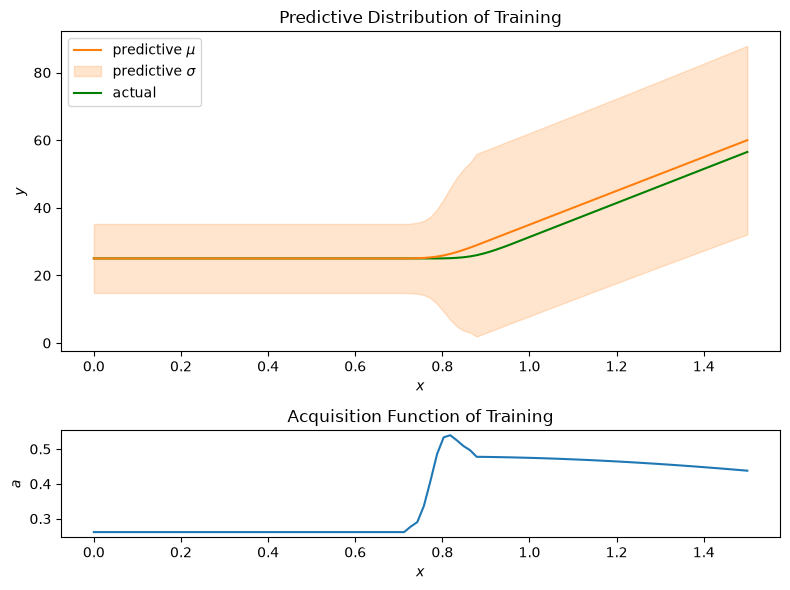

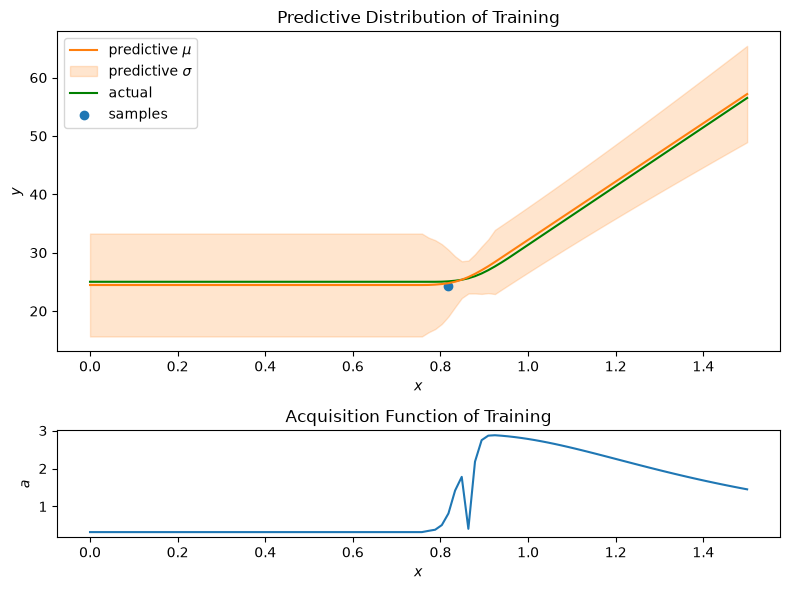

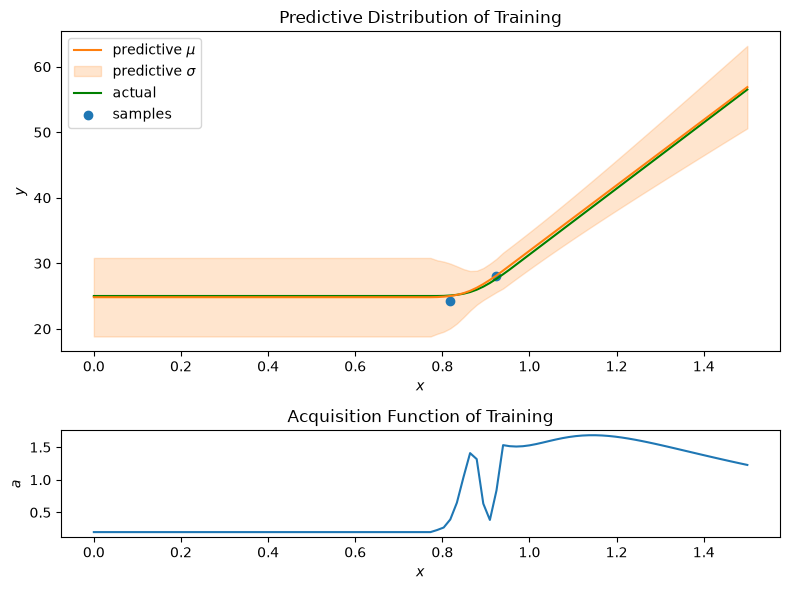

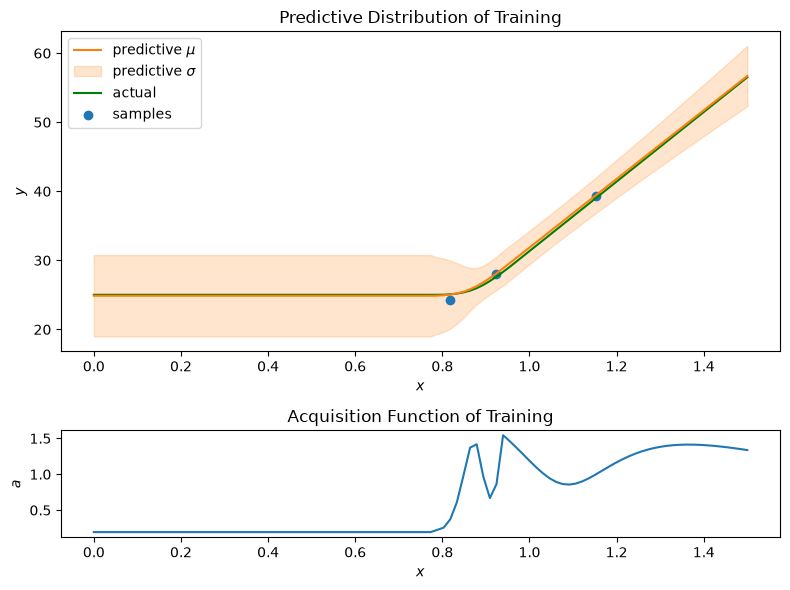

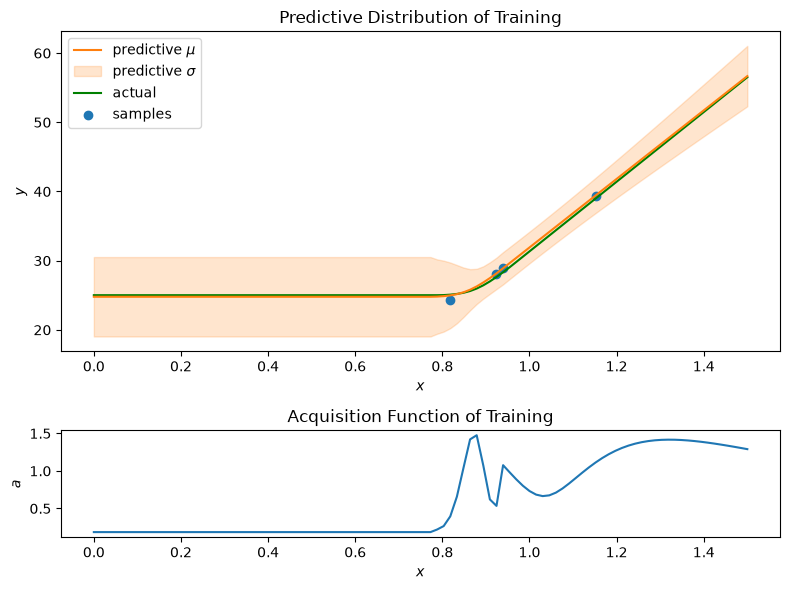

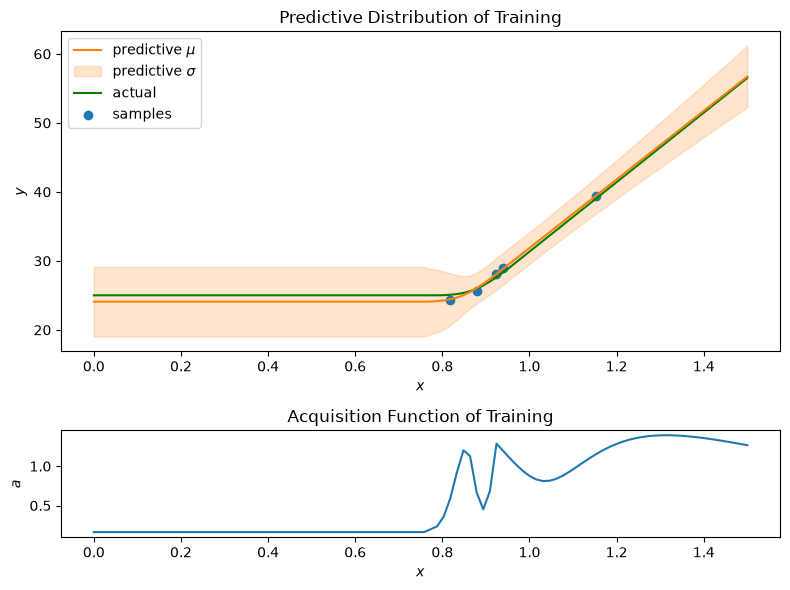

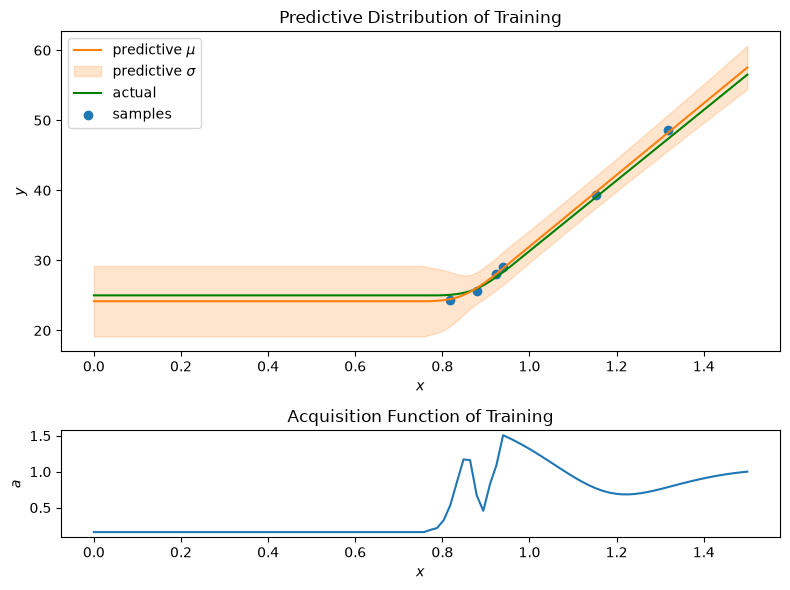

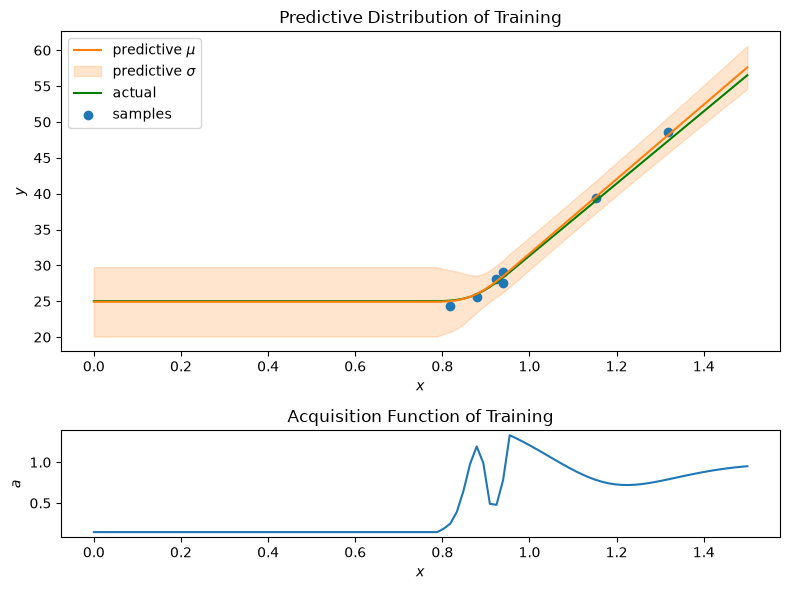

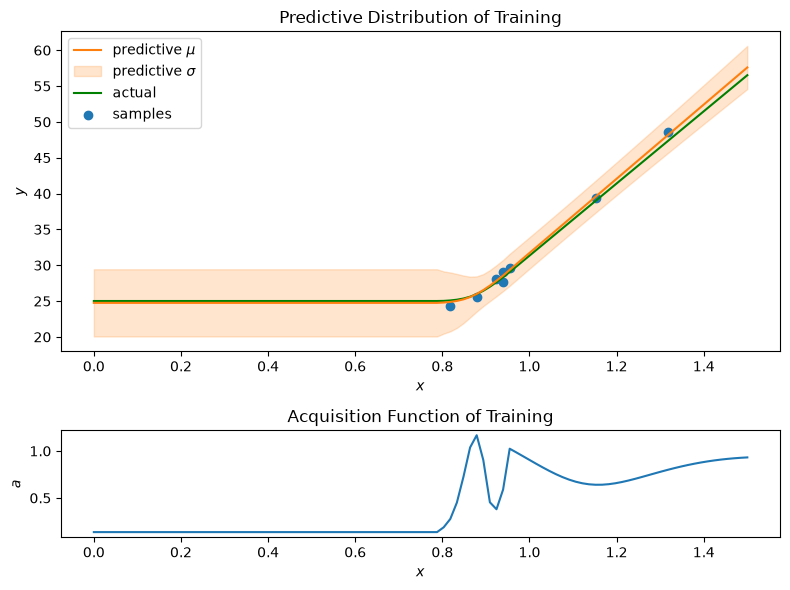

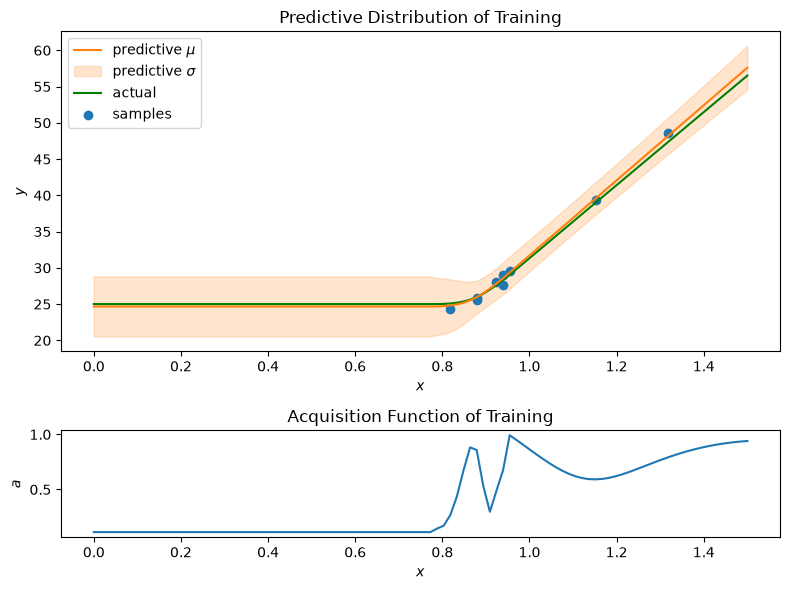

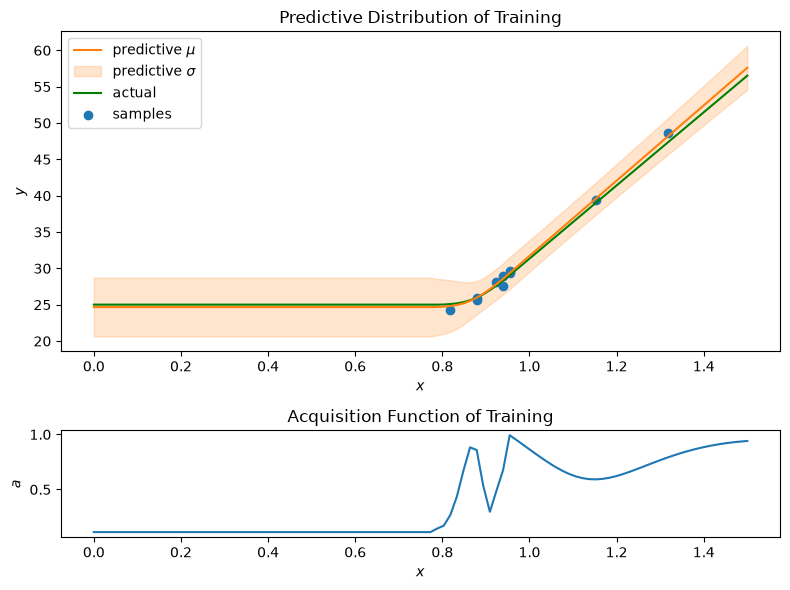

In [25]:
apf.plot_predictive_acq_train_iter(y=y_cf_p)

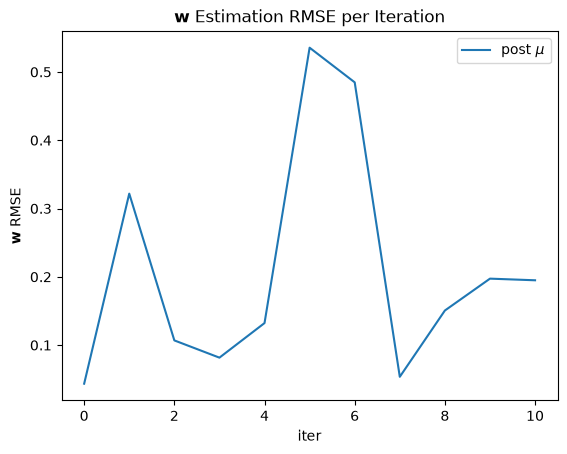

In [26]:
apf.plot_w_rmse(cf_opt_p)

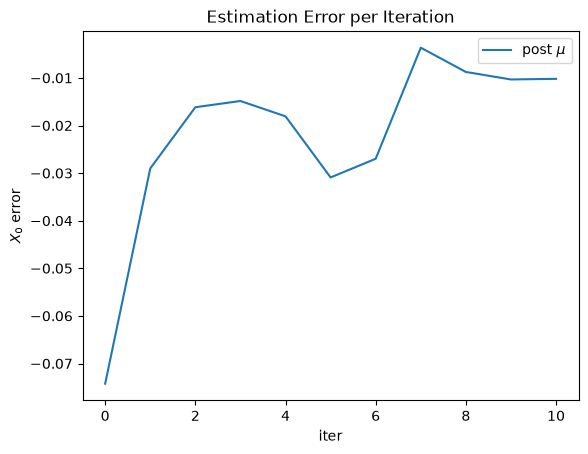

In [27]:
apf.plot_w_i_err(cf_opt_p, 1, w_i_name="$X_0$")

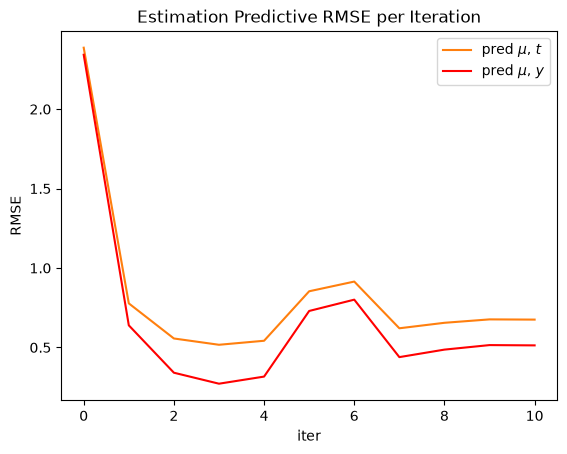

In [28]:
apf.plot_predictive_rmse(t_p, y_cf_p)

In [29]:
%timeit apf.fit_sampler_reset()

29.9 ms ± 1.13 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [30]:
%lprun -f apf.fit apf.fit_sampler_reset()

Timer unit: 1e-07 s

Total time: 0.0269186 s
File: C:\Users\djbasil\Documents\GitHub\PRISMA_sandialabs\PRISMA\src\prisma\apf\api\active_parameter_fit.py
Function: AbstractActiveParameterFit.fit at line 42

Line #      Hits         Time  Per Hit   % Time  Line Contents
    42                                               def fit(self):
    43        11        211.0     19.2      0.1          for i in range(self.sample_ct):
    44        10      15536.0   1553.6      5.8              x_next, acq_val_next = self._acquisition_f(i)
    45        10     141190.0  14119.0     52.5              t_next = self.t_sampler.sample(x_next)
    46        10        928.0     92.8      0.3              self.x_n_jnp, self.t_n_jnp, self.acq_val_jnp, \
    47        10        612.0     61.2      0.2                  self.phi_n_jnp, self.m_prior_jnp, self.var_prior_jnp \
    48        20     110481.0   5524.1     41.0                  = posterior_update_j(x_next, acq_val_next, t_next,
    49        10      